# 04 Computerized Adaptive Testing: Same Precision, Fewer Questions

**Setting:** a 60-item calibrated symptom bank (healthcare). Every
extra question costs patient time and raises dropout.
**Methods:** 2PL calibration by EM, a CAT simulator (maximum-information
item selection, EAP updating, stop at posterior SD 0.3), randomesque
exposure control, and an optimized fixed short form for comparison.
**Ground truth:** each simulated patient's true trait level.

A CAT asks the most informative remaining question given the answers so
far. Patients with mild symptoms never see items about severe ones, and
the test stops once the score is precise enough.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_root = pathlib.Path.cwd()
if _root.name == "notebooks":
    _root = _root.parent
sys.path.insert(0, str(_root / "src"))
FIG_DIR = _root / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
# Categorical slots (validated palette), plus ink for the known truth
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#8a8984"

In [2]:
from surveyhub.simulate import bank_2pl, simulate_irt, simulate_responses
from surveyhub.irt import fit_2pl, eap_scores, simulate_cat, fixed_form

## 1. Calibrate the bank

Item parameters are estimated from a calibration sample of 3,000. The
CAT then uses these estimates, not the true values, as it would in
practice. Answers are always generated from the true parameters.

In [3]:
true_bank = bank_2pl(60, a_range=(1.2, 2.5), b_range=(-2.5, 2.5), seed=41)
calib = simulate_irt(true_bank, 3000, seed=42)
model = fit_2pl(calib.X)
est_bank = model.bank
print(f"calibration: a r = {np.corrcoef(model.a, true_bank.a)[0, 1]:.3f}, "
      f"b r = {np.corrcoef(model.b[:, 0], true_bank.b[:, 0])[0, 1]:.4f}")

calibration: a r = 0.968, b r = 0.9993


## 2. Four ways to score 1,000 new patients

* **Full bank:** all 60 items.
* **CAT:** stop when the posterior SD is at most 0.3 (reliability about 0.91).
* **CAT, randomesque:** pick at random among the 5 most informative
  items, so no single item is overexposed.
* **Fixed short form:** the most informative items over the trait range,
  with as many items as the CAT used on average.

In [4]:
rng = np.random.default_rng(43)
theta = rng.normal(size=1000)
X_full = simulate_responses(true_bank, theta, seed=44)
th_full, se_full = eap_scores(est_bank.a, est_bank.d, X_full)

cat = simulate_cat(est_bank, theta, true_bank=true_bank, se_stop=0.3, seed=45)
cat_r = simulate_cat(est_bank, theta, true_bank=true_bank, se_stop=0.3, top_k=5, seed=46)
L = int(round(cat.n_items.mean()))
form = fixed_form(est_bank, L)
th_fix, se_fix = eap_scores(est_bank.a[form], est_bank.d[form], X_full[:, form])

def rmse(x):
    return np.sqrt(np.mean((x - theta) ** 2))

print(f"{'method':<22s} {'items (mean)':>13s} {'RMSE':>6s} {'corr':>6s} {'max exposure':>13s}")
print(f"{'full bank':<22s} {60:13.1f} {rmse(th_full):6.3f} {np.corrcoef(th_full, theta)[0, 1]:6.3f} {1.0:13.2f}")
print(f"{'CAT (SE 0.3)':<22s} {cat.n_items.mean():13.1f} {rmse(cat.theta_hat):6.3f} "
      f"{np.corrcoef(cat.theta_hat, theta)[0, 1]:6.3f} {cat.exposure.max():13.2f}")
print(f"{'CAT randomesque':<22s} {cat_r.n_items.mean():13.1f} {rmse(cat_r.theta_hat):6.3f} "
      f"{np.corrcoef(cat_r.theta_hat, theta)[0, 1]:6.3f} {cat_r.exposure.max():13.2f}")
print(f"{'fixed short form':<22s} {L:13.1f} {rmse(th_fix):6.3f} {np.corrcoef(th_fix, theta)[0, 1]:6.3f} {1.0:13.2f}")
print(f"\nCAT stopped by the SE rule for {np.mean(cat.n_items < 60):.1%} of patients; "
      f"{np.mean(cat.n_items <= 15):.0%} needed 15 items or fewer")

method                  items (mean)   RMSE   corr  max exposure
full bank                       60.0  0.208  0.978          1.00
CAT (SE 0.3)                    12.2  0.291  0.957          1.00
CAT randomesque                 13.0  0.300  0.954          0.70
fixed short form                12.0  0.364  0.932          1.00

CAT stopped by the SE rule for 99.2% of patients; 97% needed 15 items or fewer


## 3. Where the precision goes

Average error is only part of the story. The fixed form spends its items
near the middle of the trait, so patients at the extremes are measured
poorly. The CAT keeps precision roughly flat across the range.

In [5]:
edges = np.arange(-2.75, 2.76, 0.5)
mids = (edges[:-1] + edges[1:]) / 2
def cond_rmse(est):
    out = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (theta >= lo) & (theta < hi)
        out.append(np.sqrt(np.mean((est[m] - theta[m]) ** 2)) if m.sum() >= 10 else np.nan)
    return np.array(out)

cr_full, cr_cat, cr_fix = cond_rmse(th_full), cond_rmse(cat.theta_hat), cond_rmse(th_fix)
print(f"{'theta bin':>10s} {'full':>6s} {'CAT':>6s} {'fixed':>6s}")
for m_, a, b, c in zip(mids, cr_full, cr_cat, cr_fix):
    print(f"{m_:+10.2f} {a:6.3f} {b:6.3f} {c:6.3f}")

 theta bin   full    CAT  fixed
     -2.50  0.276  0.216  0.815
     -2.00  0.263  0.325  0.551
     -1.50  0.256  0.350  0.391
     -1.00  0.221  0.307  0.365
     -0.50  0.195  0.286  0.298
     +0.00  0.205  0.269  0.284
     +0.50  0.178  0.293  0.267
     +1.00  0.203  0.284  0.396
     +1.50  0.175  0.281  0.340
     +2.00  0.211  0.274  0.384
     +2.50  0.324  0.257  0.776


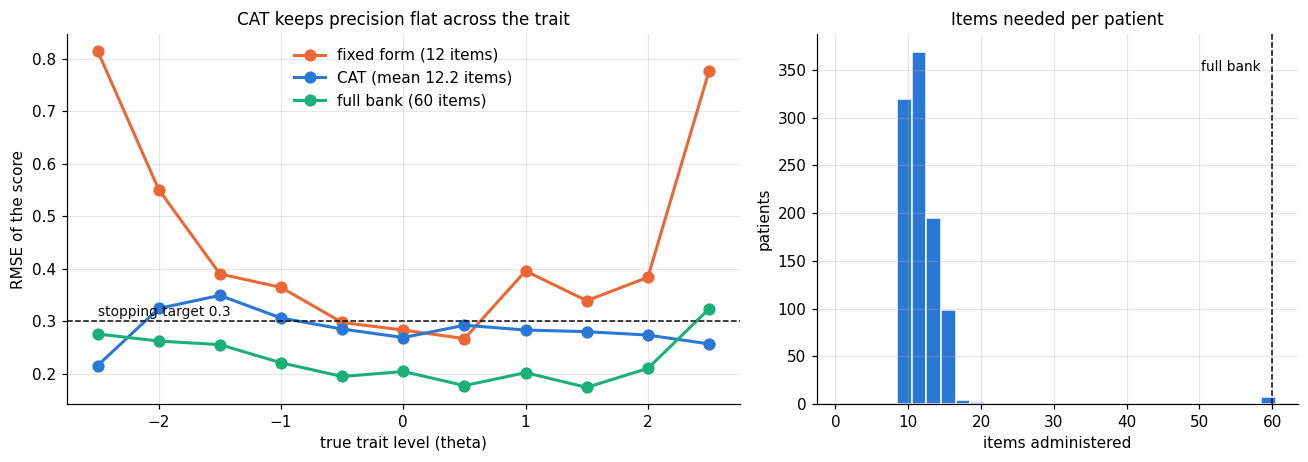

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.4, 1]})
ax1.plot(mids, cr_fix, "o-", color=ORANGE, lw=2, ms=7, label=f"fixed form ({L} items)")
ax1.plot(mids, cr_cat, "o-", color=BLUE, lw=2, ms=7, label=f"CAT (mean {cat.n_items.mean():.1f} items)")
ax1.plot(mids, cr_full, "o-", color=AQUA, lw=2, ms=7, label="full bank (60 items)")
ax1.axhline(0.3, color=INK, ls="--", lw=1)
ax1.text(mids[0], 0.31, "stopping target 0.3", fontsize=9, color=INK)
ax1.set_xlabel("true trait level (theta)")
ax1.set_ylabel("RMSE of the score")
ax1.set_title("CAT keeps precision flat across the trait", fontsize=11)
ax1.legend(frameon=False)

ax2.hist(cat.n_items, bins=np.arange(0.5, 61.5, 2), color=BLUE, edgecolor="white")
ax2.axvline(60, color=INK, lw=1, ls="--")
ax2.text(59, ax2.get_ylim()[1] * 0.9, "full bank ", ha="right", fontsize=9)
ax2.set_xlabel("items administered")
ax2.set_ylabel("patients")
ax2.set_title("Items needed per patient", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "cat_efficiency.png", dpi=150, bbox_inches="tight")
plt.show()

## Takeaways

* A CAT meets its precision target with about a fifth of the bank. The
  full 60-item test is more precise still, but at five times the
  respondent burden.
* A fixed short form of the same average length is fine in the middle
  of the trait and three to four times worse at the extremes, which is
  often where clinical decisions are made.
* Pure maximum-information selection overuses the best items.
  Randomesque selection caps exposure at a small cost in length.
* A CAT is only as good as its calibration. Here the bank was
  calibrated on 3,000 respondents and checked for fit first.